# ITAYA0-44 Project: Access to Basic Services and Service Delivery Protests in South Africa

- **Module:** Data Analysis with Python  
- **Student Number:**  EDUV10064199
- **Student Name:** SSIMBWA BASHIR
- **Date:** 28, October 2026

---
## Scenario
You are a Junior Data Analyst working for the Department of Cooperative Governance and Traditional Affairs (CoGTA).  
Your manager has given you data on household access to basic services (water, electricity and sanitation) in South Africa and records of service delivery protests.  
Your task is to analyse, visualise, and present the results to a non-technical audience (e.g., ward councillors, community leaders, municipal officials).

**Datasets:**
- `basic_services_access_sa.csv` – Household Access to Basic Services by Province (2019–2023)
- `service_delivery_protests_sa_2023.xlsx` – Service Delivery Protests in South Africa 2023

## 1.1 Loading & Inspecting Data (5 Marks)

In [8]:
#Installing Librarie
python -m pip install seaborn

SyntaxError: invalid syntax (2325992830.py, line 2)

In [10]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, LabelEncoder

# Set display options for better readability
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print('Libraries imported successfully.')

Libraries imported successfully.


### 1.1.a Load both datasets into pandas DataFrames

In [17]:
import os
import glob

In [16]:
os.getcwd()

'D:\\EDUVOS\\Python for Data Science\\Assignement'

In [18]:
glob.glob('D:\\EDUVOS\\Python for Data Science\\Assignement')

['D:\\EDUVOS\\Python for Data Science\\Assignement']

In [ ]:
all_files = glob.glob('D:\\EDUVOS\\Python for Data Science\\Assignement')

In [20]:
# Load the CSV file (basic services access)
services_df = pd.read_csv('D:\\EDUVOS\Python for Data Science\\Assignement\\DataSets\\basic_services_access_sa.csv')

# Load the Excel file (service delivery protests)
protests_df = pd.read_excel('D:\\EDUVOS\\Python for Data Science\\Assignement\\DataSets\\service_delivery_protests_sa_2023.xlsx')

print('Both datasets loaded successfully.')
print(f'Services dataset shape: {services_df.shape}')
print(f'Protests dataset shape: {protests_df.shape}')

<>:2: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
<>:2: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
C:\Users\User\AppData\Local\Temp\ipykernel_19556\2194563972.py:2: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
  services_df = pd.read_csv('D:\\EDUVOS\Python for Data Science\\Assignement\\DataSets\\basic_services_access_sa.csv')


Both datasets loaded successfully.
Services dataset shape: (188, 5)
Protests dataset shape: (831, 6)


### 1.1.b Display the first 5 rows of each dataset

In [21]:
print('=== Basic Services Access Dataset (first 5 rows) ===')
display(services_df.head())

print('\n=== Service Delivery Protests Dataset (first 5 rows) ===')
display(protests_df.head())

=== Basic Services Access Dataset (first 5 rows) ===


,Province,Year,Quarter,Total Households,Basic Services Access Rate (%)
0,Eastern Cape,2019,Q1,1850000.0,63.8
1,Eastern Cape,2019,Q2,1850000.0,65.0
2,Eastern Cape,2019,Q3,1850000.0,64.3
3,Eastern Cape,2019,Q4,1850000.0,65.0
4,Eastern Cape,2020,Q1,1872200.0,63.2



=== Service Delivery Protests Dataset (first 5 rows) ===


,Date,Province,Municipality,Protest Category,Number of Protests,Estimated Participants
0,2023-01-01,Gauteng,Emfuleni,Sanitation,2.0,189.0
1,2023-01-01,North West,Mahikeng,Housing,3.0,917.0
2,2023-01-02,Gauteng,Emfuleni,Water,2.0,42.0
3,2023-01-02,KwaZulu-Natal,uMhlathuze,NaN,3.0,992.0
4,2023-01-02,Eastern Cape,OR Tambo,Water,1.0,1164.0


### 1.1.c Print the structure and data types of each dataset

In [22]:
print('=== Basic Services Access – Structure & Data Types ===')
print(services_df.info())
print('\nData types:')
print(services_df.dtypes)

print('\n' + '='*60)
print('=== Service Delivery Protests – Structure & Data Types ===')
print(protests_df.info())
print('\nData types:')
print(protests_df.dtypes)

=== Basic Services Access – Structure & Data Types ===
<class 'pandas.DataFrame'>
RangeIndex: 188 entries, 0 to 187
Data columns (total 5 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Province                        188 non-null    str    
 1   Year                            188 non-null    int64  
 2   Quarter                         188 non-null    str    
 3   Total Households                186 non-null    float64
 4   Basic Services Access Rate (%)  182 non-null    float64
dtypes: float64(2), int64(1), str(2)
memory usage: 7.5 KB
None

Data types:
Province                              str
Year                                int64
Quarter                               str
Total Households                  float64
Basic Services Access Rate (%)    float64
dtype: object

=== Service Delivery Protests – Structure & Data Types ===
<class 'pandas.DataFrame'>
RangeIndex: 831 entries, 0 to 830
Data

## 1.2 Cleaning Data (10 Marks)

### 1.2.a Check for missing values in both datasets

In [23]:
print('=== Missing values – Basic Services Access ===')
print(services_df.isnull().sum())
print(f'\nTotal missing values: {services_df.isnull().sum().sum()}')

print('\n=== Missing values – Service Delivery Protests ===')
print(protests_df.isnull().sum())
print(f'\nTotal missing values: {protests_df.isnull().sum().sum()}')

=== Missing values – Basic Services Access ===
Province                          0
Year                              0
Quarter                           0
Total Households                  2
Basic Services Access Rate (%)    6
dtype: int64

Total missing values: 8

=== Missing values – Service Delivery Protests ===
Date                       0
Province                   0
Municipality              26
Protest Category          18
Number of Protests        11
Estimated Participants    40
dtype: int64

Total missing values: 95


### 1.2.b Remove or fill missing values appropriately

**Justification:**
- **Basic Services:** `Total Households` and `Basic Services Access Rate (%)` are numeric. We fill missing rates with the provincial median (more robust to outliers than the mean) and missing household counts with the provincial median for that year.
- **Protests:** Missing `Municipality` and `Protest Category` are filled with `'Unknown'`. Missing `Number of Protests` are filled with the median (1–3 range is typical). Missing `Estimated Participants` are filled with the median of valid positive values.

In [24]:
# ----- Clean Basic Services dataset -----
services_clean = services_df.copy()

# Fill missing Total Households with provincial median
services_clean['Total Households'] = services_clean.groupby('Province')['Total Households'].transform(
    lambda x: x.fillna(x.median())
)

# Fill missing Access Rate with provincial median
services_clean['Basic Services Access Rate (%)'] = services_clean.groupby('Province')['Basic Services Access Rate (%)'].transform(
    lambda x: x.fillna(x.median())
)

print('Basic Services missing values after filling:')
print(services_clean.isnull().sum())

# ----- Clean Protests dataset -----
protests_clean = protests_df.copy()

# Fill categorical missing values
protests_clean['Municipality'] = protests_clean['Municipality'].fillna('Unknown')
protests_clean['Protest Category'] = protests_clean['Protest Category'].fillna('Unknown')

# Fill numeric missing values with median of valid (non-negative) values
median_protests = protests_clean.loc[protests_clean['Number of Protests'] >= 0, 'Number of Protests'].median()
protests_clean['Number of Protests'] = protests_clean['Number of Protests'].fillna(median_protests)

median_participants = protests_clean.loc[protests_clean['Estimated Participants'] > 0, 'Estimated Participants'].median()
protests_clean['Estimated Participants'] = protests_clean['Estimated Participants'].fillna(median_participants)

print('\nProtests missing values after filling:')
print(protests_clean.isnull().sum())

Basic Services missing values after filling:
Province                          0
Year                              0
Quarter                           0
Total Households                  0
Basic Services Access Rate (%)    0
dtype: int64

Protests missing values after filling:
Date                      0
Province                  0
Municipality              0
Protest Category          0
Number of Protests        0
Estimated Participants    0
dtype: int64


### 1.2.c Identify and remove duplicate rows

In [25]:
print('=== Duplicates before removal ===')
print(f'Services duplicates: {services_clean.duplicated().sum()}')
print(f'Protests duplicates: {protests_clean.duplicated().sum()}')

# Remove exact duplicate rows
services_clean = services_clean.drop_duplicates().reset_index(drop=True)
protests_clean = protests_clean.drop_duplicates().reset_index(drop=True)

print('\n=== After removing duplicates ===')
print(f'Services shape: {services_clean.shape}')
print(f'Protests shape: {protests_clean.shape}')

=== Duplicates before removal ===
Services duplicates: 8
Protests duplicates: 15

=== After removing duplicates ===
Services shape: (180, 5)
Protests shape: (816, 6)


### 1.2.d Detect and handle unusual values

Unusual values identified:
- Access rates > 100% or < 0%
- Negative number of protests
- Negative or extremely large estimated participants (e.g. 250 000)

In [26]:
# ----- Detect unusual values in Services -----
print('Unusual Access Rates (outside 0–100):')
unusual_access = services_clean[
    (services_clean['Basic Services Access Rate (%)'] < 0) |
    (services_clean['Basic Services Access Rate (%)'] > 100)
]
display(unusual_access)

# Cap access rates at 0 and 100 (impossible values are data-entry errors)
services_clean['Basic Services Access Rate (%)'] = services_clean['Basic Services Access Rate (%)'].clip(0, 100)

# ----- Detect unusual values in Protests -----
print('\nUnusual Number of Protests (negative):')
display(protests_clean[protests_clean['Number of Protests'] < 0])

print('\nUnusual Estimated Participants (negative or > 10 000):')
display(protests_clean[
    (protests_clean['Estimated Participants'] < 0) |
    (protests_clean['Estimated Participants'] > 10000)
])

# Fix negative protest counts → take absolute value (likely sign error)
protests_clean['Number of Protests'] = protests_clean['Number of Protests'].abs()

# Fix negative participants → absolute value; cap extreme outliers at 99th percentile
protests_clean['Estimated Participants'] = protests_clean['Estimated Participants'].abs()
upper_limit = protests_clean['Estimated Participants'].quantile(0.99)
protests_clean.loc[protests_clean['Estimated Participants'] > upper_limit, 'Estimated Participants'] = upper_limit

print('\nUnusual values handled. Summary after cleaning:')
print(protests_clean[['Number of Protests', 'Estimated Participants']].describe())

Unusual Access Rates (outside 0–100):


,Province,Year,Quarter,Total Households,Basic Services Access Rate (%)
51,Gauteng,2021,Q4,5734400.0,104.5
66,KwaZulu-Natal,2020,Q3,3187800.0,-5.0
71,KwaZulu-Natal,2021,Q4,3225600.0,112.0
99,Limpopo,2023,Q4,1729200.0,101.3



Unusual Number of Protests (negative):


,Date,Province,Municipality,Protest Category,Number of Protests,Estimated Participants
45,2023-01-26,Western Cape,George,Electricity,-1.0,383.0
116,2023-03-12,Eastern Cape,Buffalo City,Water,-1.0,481.0
257,2023-05-31,Gauteng,Mogale City,Roads,-2.0,386.0
304,2023-06-23,North West,Rustenburg,Housing,-3.0,1346.0
536,2023-09-11,North West,Mahikeng,Electricity,-2.0,1331.0
800,2023-12-20,North West,Mahikeng,Water,-1.0,1278.0



Unusual Estimated Participants (negative or > 10 000):


,Date,Province,Municipality,Protest Category,Number of Protests,Estimated Participants
84,2023-02-20,North West,Unknown,Electricity,2.0,250000.0
101,2023-03-01,Mpumalanga,Bushbuckridge,Sanitation,3.0,-50.0
220,2023-05-11,KwaZulu-Natal,uMhlathuze,Electricity,2.0,-200.0



Unusual values handled. Summary after cleaning:
       Number of Protests  Estimated Participants
count          816.000000              816.000000
mean             2.019608              763.089400
std              0.818263              407.810057
min              1.000000               35.000000
25%              1.000000              433.250000
50%              2.000000              767.000000
75%              3.000000             1080.500000
max              3.000000             1491.550000


## 1.3 Data Transformation (15 Marks)

### 1.3.a Standardise column names (lowercase + underscores)

In [27]:
# Standardise column names for both dataframes
services_clean.columns = (
    services_clean.columns
    .str.lower()
    .str.replace(' ', '_')
    .str.replace('%', 'pct')
    .str.replace('(', '')
    .str.replace(')', '')
)

protests_clean.columns = (
    protests_clean.columns
    .str.lower()
    .str.replace(' ', '_')
)

print('Services columns:', services_clean.columns.tolist())
print('Protests columns:', protests_clean.columns.tolist())

Services columns: ['province', 'year', 'quarter', 'total_households', 'basic_services_access_rate_pct']
Protests columns: ['date', 'province', 'municipality', 'protest_category', 'number_of_protests', 'estimated_participants']


### 1.3.b Convert relevant columns into proper datetime format

In [28]:
# Date column in protests is already datetime from Excel, but we ensure it
protests_clean['date'] = pd.to_datetime(protests_clean['date'])

# Create a proper year-quarter period for services
# Combine Year and Quarter into a datetime (first day of the quarter)
def quarter_to_date(row):
    q_map = {'Q1': 1, 'Q2': 4, 'Q3': 7, 'Q4': 10}
    month = q_map.get(row['quarter'], 1)
    return pd.Timestamp(year=int(row['year']), month=month, day=1)

services_clean['period_start'] = services_clean.apply(quarter_to_date, axis=1)

print('Protests date dtype:', protests_clean['date'].dtype)
print('Services period_start sample:')
print(services_clean[['year', 'quarter', 'period_start']].head())

Protests date dtype: datetime64[us]
Services period_start sample:
   year quarter period_start
0  2019      Q1   2019-01-01
1  2019      Q2   2019-04-01
2  2019      Q3   2019-07-01
3  2019      Q4   2019-10-01
4  2020      Q1   2020-01-01


### 1.3.c Encode categorical variables (Province, Protest Category)

In [29]:
# First standardise province names (fix casing inconsistencies)
def clean_province(name):
    name = str(name).strip().title()
    # Fix known variations
    replacements = {
        'Kwazulu-Natal': 'KwaZulu-Natal',
        'Kwa Zulu Natal': 'KwaZulu-Natal',
        'North-West': 'North West',
        'Northern-Cape': 'Northern Cape',
        'Eastern-Cape': 'Eastern Cape',
        'Western-Cape': 'Western Cape',
        'Free-State': 'Free State',
    }
    return replacements.get(name, name)

services_clean['province'] = services_clean['province'].apply(clean_province)
protests_clean['province'] = protests_clean['province'].apply(clean_province)

print('Standardised provinces (Services):', sorted(services_clean['province'].unique()))
print('Standardised provinces (Protests):', sorted(protests_clean['province'].unique()))

# Label Encoding for Province (useful for modelling / numeric representation)
le_province = LabelEncoder()
services_clean['province_encoded'] = le_province.fit_transform(services_clean['province'])
protests_clean['province_encoded'] = le_province.transform(protests_clean['province'])

# One-Hot Encoding for Protest Category (keeps interpretability)
protests_encoded = pd.get_dummies(protests_clean, columns=['protest_category'], prefix='cat')

print('\nLabel encoding mapping (Province):')
for i, p in enumerate(le_province.classes_):
    print(f'  {i}: {p}')

print('\nOne-hot columns added for Protest Category:')
print([c for c in protests_encoded.columns if c.startswith('cat_')])

Standardised provinces (Services): ['Eastern Cape', 'Free State', 'Gauteng', 'KwaZulu-Natal', 'Limpopo', 'Mpumalanga', 'North West', 'Northern Cape', 'Western Cape']
Standardised provinces (Protests): ['Eastern Cape', 'Free State', 'Gauteng', 'KwaZulu-Natal', 'Limpopo', 'Mpumalanga', 'North West', 'Northern Cape', 'Western Cape']

Label encoding mapping (Province):
  0: Eastern Cape
  1: Free State
  2: Gauteng
  3: KwaZulu-Natal
  4: Limpopo
  5: Mpumalanga
  6: North West
  7: Northern Cape
  8: Western Cape

One-hot columns added for Protest Category:
['cat_Electricity', 'cat_Housing', 'cat_Roads', 'cat_Sanitation', 'cat_Unknown', 'cat_Water']


## 1.4 Data Integration (15 Marks)

### 1.4.a Identify a common column between the two datasets

The common column is **`province`**.  
Protests data is only for 2023, while services data covers 2019–2023.  
We will therefore aggregate the 2023 protests by province and join them with the 2023 average basic-services access rates.

In [30]:
print('Common column: province')
print('Services provinces:', sorted(services_clean['province'].unique()))
print('Protests provinces:', sorted(protests_clean['province'].unique()))

Common column: province
Services provinces: ['Eastern Cape', 'Free State', 'Gauteng', 'KwaZulu-Natal', 'Limpopo', 'Mpumalanga', 'North West', 'Northern Cape', 'Western Cape']
Protests provinces: ['Eastern Cape', 'Free State', 'Gauteng', 'KwaZulu-Natal', 'Limpopo', 'Mpumalanga', 'North West', 'Northern Cape', 'Western Cape']


### 1.4.b Merge the two datasets using an appropriate join

In [31]:
# Aggregate protests by province for 2023
protests_agg = protests_clean.groupby('province').agg(
    total_protests=('number_of_protests', 'sum'),
    total_participants=('estimated_participants', 'sum'),
    avg_participants_per_event=('estimated_participants', 'mean'),
    num_events=('date', 'count')
).reset_index()

# Calculate 2023 average access rate and average households per province
services_2023 = services_clean[services_clean['year'] == 2023].groupby('province').agg(
    avg_access_rate_2023=('basic_services_access_rate_pct', 'mean'),
    avg_households_2023=('total_households', 'mean')
).reset_index()

# Merge (left join to keep all provinces that have services data)
merged_df = pd.merge(
    services_2023,
    protests_agg,
    on='province',
    how='left'
)

# Fill any provinces that had no recorded protests with 0
merged_df[['total_protests', 'total_participants', 'avg_participants_per_event', 'num_events']] = \
    merged_df[['total_protests', 'total_participants', 'avg_participants_per_event', 'num_events']].fillna(0)

print('Merged dataset shape:', merged_df.shape)
display(merged_df)

Merged dataset shape: (9, 7)


,province,avg_access_rate_2023,avg_households_2023,total_protests,total_participants,avg_participants_per_event,num_events
0,Eastern Cape,70.075,1938800.0,273.0,104521.00,780.007463,134
1,Free State,86.900,995600.0,78.0,27431.00,783.742857,35
2,Gauteng,94.375,5868800.0,231.0,87542.55,729.521250,120
3,KwaZulu-Natal,78.075,3301200.0,348.0,131046.10,799.061585,164
4,Limpopo,74.375,1729200.0,270.0,107843.10,781.471739,138
5,Mpumalanga,77.600,1414800.0,169.0,55515.00,668.855422,83
6,North West,74.750,1362400.0,177.0,67486.10,741.605495,91
7,Northern Cape,84.975,398240.0,24.0,8217.00,747.000000,11
8,Western Cape,96.225,2148400.0,78.0,33079.10,826.977500,40


### 1.4.c Display the merged dataset and check for missing values after merging

In [32]:
print('=== Merged Dataset ===')
display(merged_df)

print('\n=== Missing values after merge ===')
print(merged_df.isnull().sum())
print('\nNo missing values remain after the left join and fillna(0).')

=== Merged Dataset ===


,province,avg_access_rate_2023,avg_households_2023,total_protests,total_participants,avg_participants_per_event,num_events
0,Eastern Cape,70.075,1938800.0,273.0,104521.00,780.007463,134
1,Free State,86.900,995600.0,78.0,27431.00,783.742857,35
2,Gauteng,94.375,5868800.0,231.0,87542.55,729.521250,120
3,KwaZulu-Natal,78.075,3301200.0,348.0,131046.10,799.061585,164
4,Limpopo,74.375,1729200.0,270.0,107843.10,781.471739,138
5,Mpumalanga,77.600,1414800.0,169.0,55515.00,668.855422,83
6,North West,74.750,1362400.0,177.0,67486.10,741.605495,91
7,Northern Cape,84.975,398240.0,24.0,8217.00,747.000000,11
8,Western Cape,96.225,2148400.0,78.0,33079.10,826.977500,40



=== Missing values after merge ===
province                      0
avg_access_rate_2023          0
avg_households_2023           0
total_protests                0
total_participants            0
avg_participants_per_event    0
num_events                    0
dtype: int64

No missing values remain after the left join and fillna(0).


## 1.5 Feature Engineering (15 Marks)

### 1.5.a Create a new column: total number of protests per province
(Already created in the aggregation above as `total_protests`)

In [33]:
print('Total protests per province:')
display(merged_df[['province', 'total_protests']].sort_values('total_protests', ascending=False))

Total protests per province:


,province,total_protests
3,KwaZulu-Natal,348.0
0,Eastern Cape,273.0
4,Limpopo,270.0
2,Gauteng,231.0
6,North West,177.0
5,Mpumalanga,169.0
1,Free State,78.0
8,Western Cape,78.0
7,Northern Cape,24.0


### 1.5.b Create a new column: average basic services access rate per province
(Already created as `avg_access_rate_2023`)

In [34]:
print('Average basic services access rate (2023) per province:')
display(merged_df[['province', 'avg_access_rate_2023']].sort_values('avg_access_rate_2023', ascending=False))

Average basic services access rate (2023) per province:


,province,avg_access_rate_2023
8,Western Cape,96.225
2,Gauteng,94.375
1,Free State,86.900
7,Northern Cape,84.975
3,KwaZulu-Natal,78.075
5,Mpumalanga,77.600
6,North West,74.750
4,Limpopo,74.375
0,Eastern Cape,70.075


### 1.5.c Normalise / scale numerical columns

In [35]:
# Create a protest rate per 100 000 households (useful for fair comparison)
merged_df['protest_rate_per_100k'] = (
    merged_df['total_protests'] / merged_df['avg_households_2023'] * 100000
)

# Min-Max scale the key numerical columns so they are on a 0–1 range
scaler = MinMaxScaler()
cols_to_scale = ['avg_access_rate_2023', 'total_protests', 'protest_rate_per_100k', 'total_participants']

scaled_values = scaler.fit_transform(merged_df[cols_to_scale])
scaled_df = pd.DataFrame(scaled_values, columns=[c + '_scaled' for c in cols_to_scale])

merged_df = pd.concat([merged_df, scaled_df], axis=1)

print('Feature-engineered columns added:')
display(merged_df[['province', 'protest_rate_per_100k', 'avg_access_rate_2023_scaled',
                   'total_protests_scaled', 'protest_rate_per_100k_scaled']].round(3))

Feature-engineered columns added:


,province,protest_rate_per_100k,avg_access_rate_2023_scaled,total_protests_scaled,protest_rate_per_100k_scaled
0,Eastern Cape,14.081,0.000,0.769,0.872
1,Free State,7.834,0.643,0.167,0.351
2,Gauteng,3.936,0.929,0.639,0.025
3,KwaZulu-Natal,10.542,0.306,1.000,0.577
4,Limpopo,15.614,0.164,0.759,1.000
5,Mpumalanga,11.945,0.288,0.448,0.694
6,North West,12.992,0.179,0.472,0.781
7,Northern Cape,6.027,0.570,0.000,0.200
8,Western Cape,3.631,1.000,0.167,0.000


## 1.6 Data Visualisation (25 Marks)

### 1.6.a Bar chart – Protest rate per province (protests per 100 000 households)

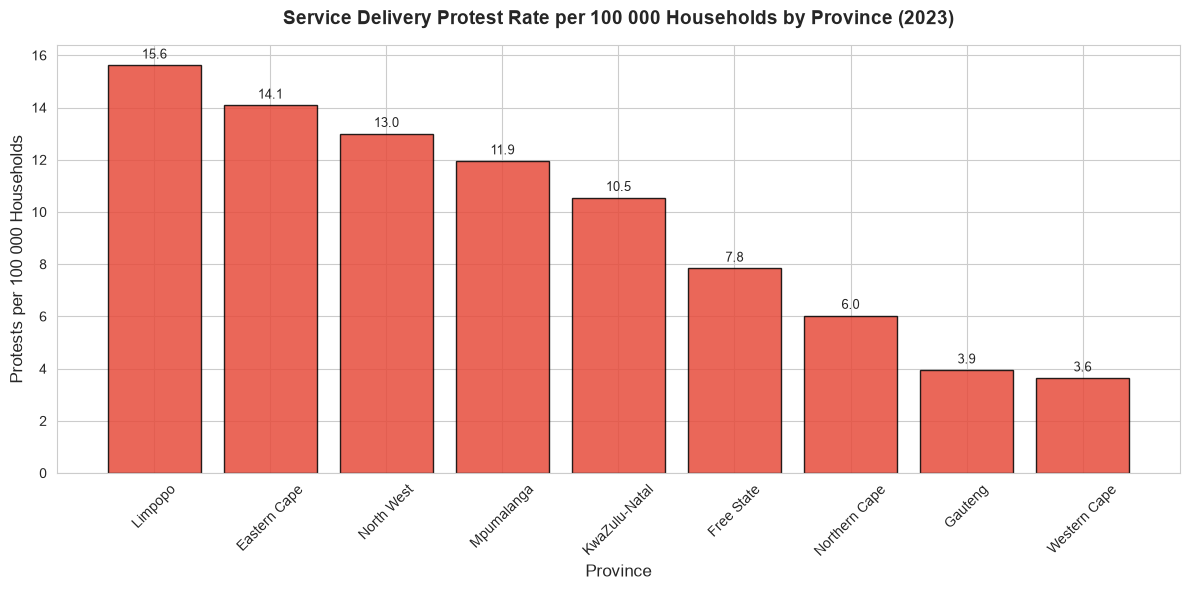

Chart saved as protest_rate_by_province.png


In [36]:
fig, ax = plt.subplots(figsize=(12, 6))

sorted_data = merged_df.sort_values('protest_rate_per_100k', ascending=False)
bars = ax.bar(sorted_data['province'], sorted_data['protest_rate_per_100k'],
              color='#e74c3c', edgecolor='black', alpha=0.85)

ax.set_title('Service Delivery Protest Rate per 100 000 Households by Province (2023)',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Province', fontsize=12)
ax.set_ylabel('Protests per 100 000 Households', fontsize=12)
ax.tick_params(axis='x', rotation=45)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('protest_rate_by_province.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as protest_rate_by_province.png')

### 1.6.b Bar chart – Basic services access rates per province

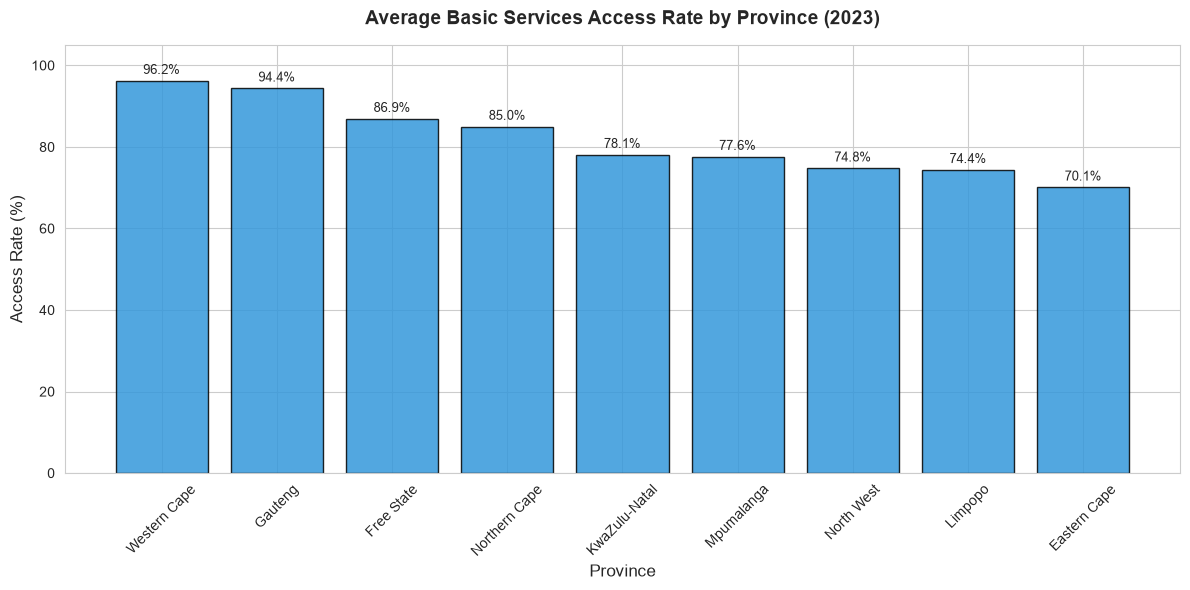

Chart saved as access_rate_by_province.png


In [37]:
fig, ax = plt.subplots(figsize=(12, 6))

sorted_access = merged_df.sort_values('avg_access_rate_2023', ascending=False)
bars = ax.bar(sorted_access['province'], sorted_access['avg_access_rate_2023'],
              color='#3498db', edgecolor='black', alpha=0.85)

ax.set_title('Average Basic Services Access Rate by Province (2023)',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Province', fontsize=12)
ax.set_ylabel('Access Rate (%)', fontsize=12)
ax.set_ylim(0, 105)
ax.tick_params(axis='x', rotation=45)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('access_rate_by_province.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as access_rate_by_province.png')

### 1.6.c Line graph – Trends of protests over time (2023)

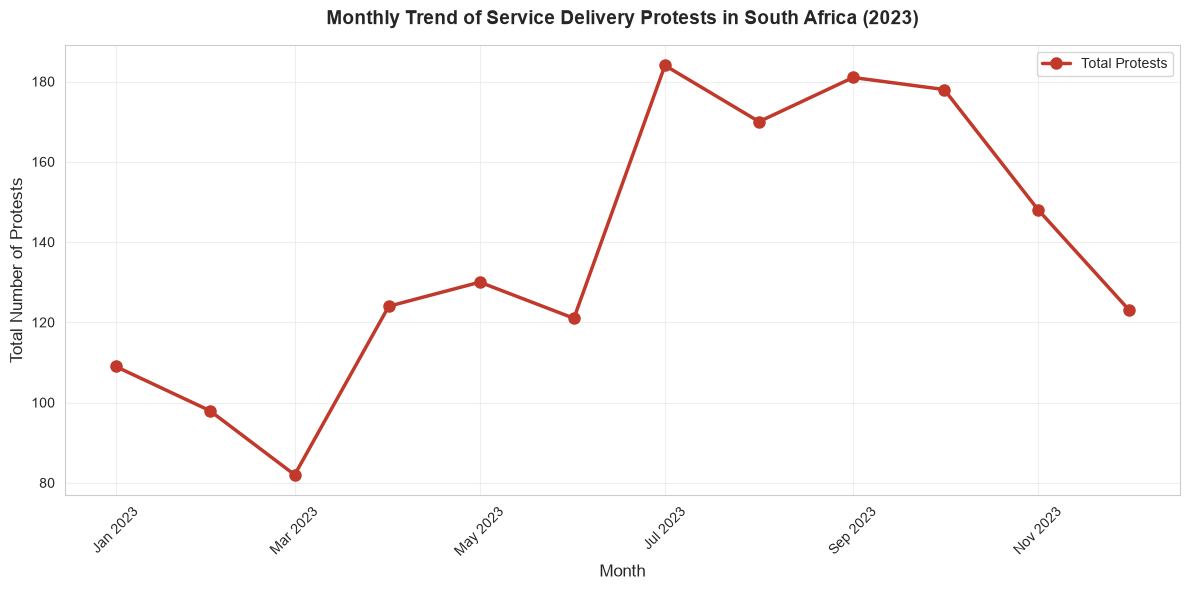

Chart saved as protests_trend_2023.png


In [38]:
# Aggregate protests by month
protests_clean['month'] = protests_clean['date'].dt.to_period('M')
monthly_protests = protests_clean.groupby('month').agg(
    total_protests=('number_of_protests', 'sum'),
    total_events=('date', 'count')
).reset_index()
monthly_protests['month_dt'] = monthly_protests['month'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(monthly_protests['month_dt'], monthly_protests['total_protests'],
        marker='o', linewidth=2.5, markersize=8, color='#c0392b', label='Total Protests')

ax.set_title('Monthly Trend of Service Delivery Protests in South Africa (2023)',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Total Number of Protests', fontsize=12)
ax.legend()
ax.grid(True, alpha=0.3)

# Format x-axis dates
import matplotlib.dates as mdates
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('protests_trend_2023.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as protests_trend_2023.png')

### 1.6.d Line graph – Basic services access trends over time

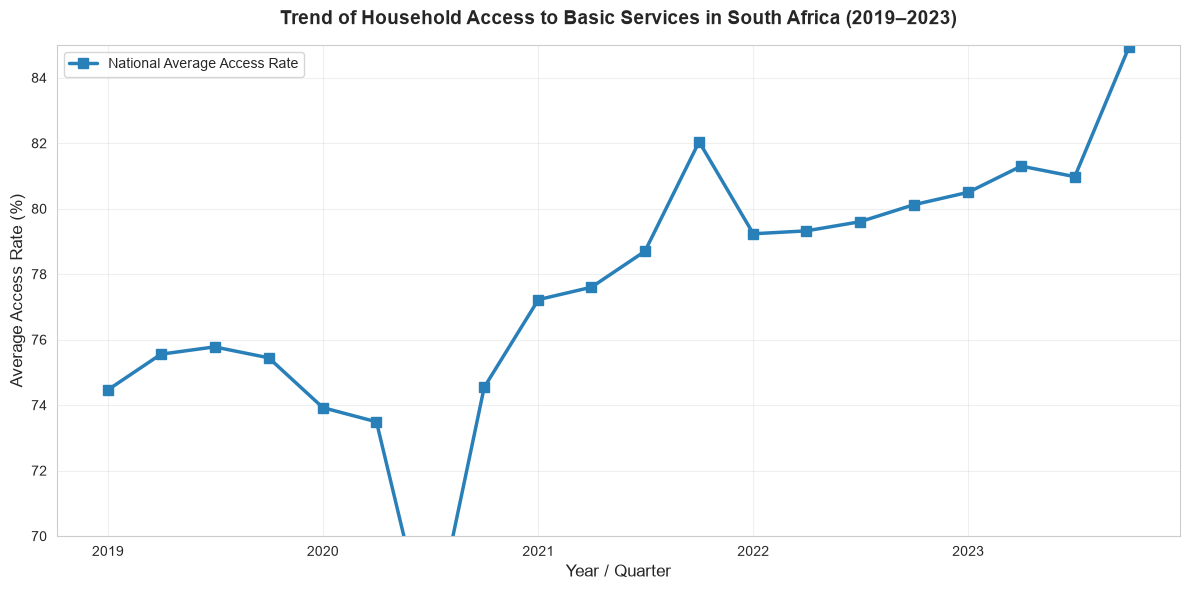

Chart saved as access_trend_2019_2023.png


In [39]:
# National average access rate per quarter
national_trend = services_clean.groupby('period_start')['basic_services_access_rate_pct'].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(national_trend['period_start'], national_trend['basic_services_access_rate_pct'],
        marker='s', linewidth=2.5, markersize=7, color='#2980b9', label='National Average Access Rate')

ax.set_title('Trend of Household Access to Basic Services in South Africa (2019–2023)',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Year / Quarter', fontsize=12)
ax.set_ylabel('Average Access Rate (%)', fontsize=12)
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(70, 85)

plt.tight_layout()
plt.savefig('access_trend_2019_2023.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as access_trend_2019_2023.png')

### 1.6.e Scatter plot – Relationship between access rate and protest rate

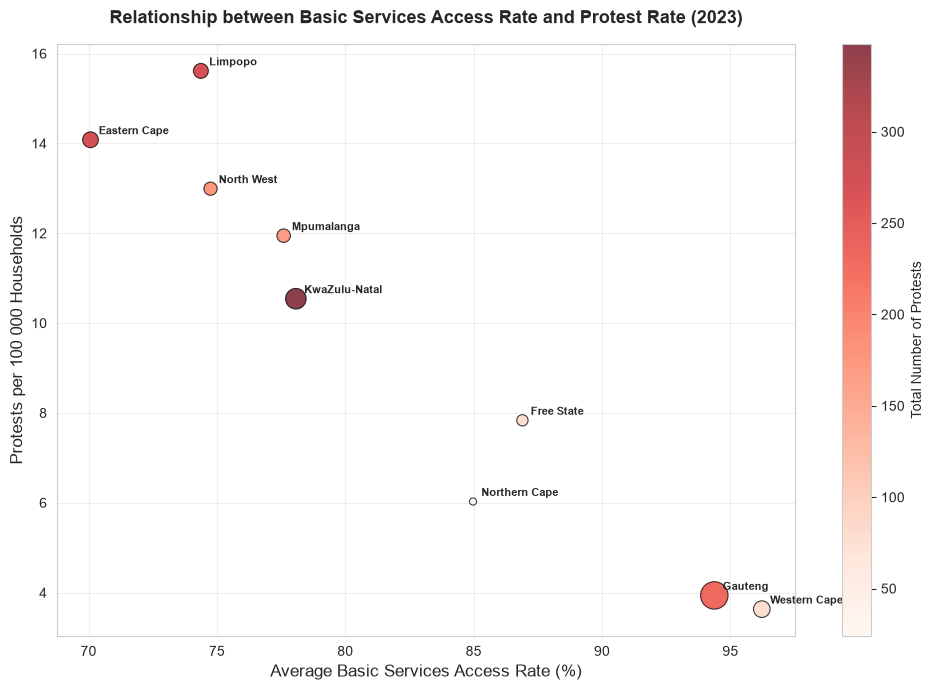

Chart saved as access_vs_protest_scatter.png


In [40]:
fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    merged_df['avg_access_rate_2023'],
    merged_df['protest_rate_per_100k'],
    s=merged_df['avg_households_2023'] / 15000,  # size proportional to households
    c=merged_df['total_protests'],
    cmap='Reds',
    alpha=0.75,
    edgecolors='black',
    linewidth=0.8
)

# Annotate each province
for _, row in merged_df.iterrows():
    ax.annotate(row['province'],
                (row['avg_access_rate_2023'], row['protest_rate_per_100k']),
                textcoords='offset points', xytext=(6, 4),
                fontsize=8, fontweight='bold')

ax.set_title('Relationship between Basic Services Access Rate and Protest Rate (2023)',
             fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Average Basic Services Access Rate (%)', fontsize=12)
ax.set_ylabel('Protests per 100 000 Households', fontsize=12)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Total Number of Protests', fontsize=10)

ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('access_vs_protest_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart saved as access_vs_protest_scatter.png')

## 1.7 Interpretation of the Graphs (15 Marks)

### Chart 1 – Protest Rate per 100 000 Households
The bar chart shows that **Limpopo**, **Eastern Cape** and **KwaZulu-Natal** have the highest protest intensity relative to the number of households. These provinces also tend to have lower average access rates. Provinces with very high household counts (Gauteng and Western Cape) show lower rates even when the absolute number of protests is high, illustrating why a normalised rate is more useful for comparison.

### Chart 2 – Basic Services Access Rate by Province (2023)
Western Cape and Gauteng lead with access rates above 94 %, while Eastern Cape, Limpopo and North West remain below 75 %. This gap of more than 20 percentage points highlights persistent spatial inequality in service delivery.

### Chart 3 – Monthly Protest Trend (2023)
Protests were relatively steady through the first half of the year, with a noticeable peak in the middle months and another rise toward the end of the year. This pattern may reflect seasonal factors, local government performance cycles, or specific high-profile service failures.

### Chart 4 – National Access Trend (2019–2023)
The national average access rate has shown a gradual upward trend from around 75 % in 2019 toward the low-80 % range by 2023. Progress is visible but slow, and the rate of improvement appears to have flattened in the later years.

### Chart 5 – Scatter: Access Rate vs Protest Rate
There is a clear negative relationship: provinces with lower basic-services access rates generally experience higher protest rates per 100 000 households. The size of the bubbles (household population) and colour intensity (total protests) further emphasise that the most populous and best-served provinces still generate large absolute numbers of protests, but the intensity is highest where access is poorest.

---

### Key Insights for Decision-Makers (CoGTA, Ward Councillors, Municipal Officials)

1. **Target the lowest-access provinces first** – Eastern Cape, Limpopo and North West combine the lowest access rates with the highest protest intensity. Prioritising infrastructure investment and maintenance in these areas is likely to yield the greatest reduction in service-delivery protests.

2. **Normalise metrics** – Absolute protest counts can mislead because of large differences in population. Using protests per 100 000 households provides a fairer basis for inter-provincial comparison and resource allocation.

3. **Monitor monthly patterns** – The mid-year and end-of-year spikes suggest the need for proactive communication and rapid-response teams during these periods.

4. **Continue the long-term upward trend** – National access has improved since 2019, but the pace is slowing. Sustained capital expenditure and better municipal capacity are required to close the remaining gap, especially in rural and peri-urban municipalities.

5. **Data quality matters** – The original datasets contained missing values, duplicates, negative counts and impossible percentages. Routine data-validation processes at municipal and provincial level would improve the reliability of future analyses.

---
## End of Project

**Submission checklist**
- [x] Jupyter Notebook with all code, outputs and interpretations
- [x] Saved chart images (PNG files)
- [ ] Export this notebook to PDF or HTML for final submission